# 02 · Auto-etiquetado del dataset

**Objetivo:** aplicar el modelo v1 sobre los frames extraídos para generar automáticamente anotaciones en formato YOLO, reduciendo el tiempo de etiquetado manual del resto del dataset.

**Contexto:** el modelo v1, aunque imperfecto, es capaz de detectar correctamente la mayoría de jugadores y árbitros. Sus predicciones se usan como punto de partida para el etiquetado, dejandome únicamente la tarea de corregir errores en lugar de etiquetar desde cero.

**Entrada:** modelo `models/best_v1.pt` y frames en `data/frames/`.

**Salida:** imágenes y anotaciones automáticas en `data/auto_labeled/`.

## 1. Configuración

In [1]:
from ultralytics import YOLO
from pathlib import Path
import os
import shutil

REPO_ROOT = Path("../..").resolve()
MODEL_PATH = REPO_ROOT / "models" / "best_v1.pt"
FRAMES_DIR = REPO_ROOT / "data" / "frames"
OUTPUT_DIR = REPO_ROOT / "data" / "auto_labeled"
CONF_THRESHOLD = 0.4

print(f"Modelo: {MODEL_PATH}")
print(f"Frames: {FRAMES_DIR}")
print(f"Salida: {OUTPUT_DIR}")
print(f"Umbral de confianza: {CONF_THRESHOLD}")

Modelo: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\models\best_v1.pt
Frames: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\frames
Salida: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\auto_labeled
Umbral de confianza: 0.4


## 2. Justificación del umbral de confianza

Se usa un umbral de confianza de 0.4, valor intermedio que equilibra dos objetivos: ser suficientemente permisivo para que el modelo proponga la mayoría de detecciones (y así reducir el trabajo de añadir cajas manualmente), pero suficientemente estricto para no generar demasiados falsos positivos que tendría que eliminar.

In [5]:
model = YOLO(str(MODEL_PATH))
print(f"Modelo cargado correctamente")
print(f"Clases: {model.names}")

Modelo cargado correctamente
Clases: {0: 'ball', 1: 'player', 2: 'referee'}


## 3. Preparación de la estructura de salida

Se crea la estructura de carpetas `images/` y `labels/` que sigue el formato esperado por YOLO y por Roboflow.

In [6]:
images_out = OUTPUT_DIR / "images"
labels_out = OUTPUT_DIR / "labels"

images_out.mkdir(parents=True, exist_ok=True)
labels_out.mkdir(parents=True, exist_ok=True)

print(f"Carpetas creadas:")
print(f"  {images_out}")
print(f"  {labels_out}")

Carpetas creadas:
  C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\auto_labeled\images
  C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\auto_labeled\labels


## 4. Inventario de frames a procesar

In [7]:
subdirs = [d for d in FRAMES_DIR.iterdir() if d.is_dir()]
total_frames = sum(len(list(d.glob("*.jpg"))) for d in subdirs)

print(f"Subcarpetas de vídeo encontradas: {len(subdirs)}")
print(f"Total de frames a procesar: {total_frames}\n")

for d in subdirs:
    n = len(list(d.glob("*.jpg")))
    print(f"  {d.name}: {n} frames")

Subcarpetas de vídeo encontradas: 12
Total de frames a procesar: 756

  A1606b0e6_0 (12): 63 frames
  A1606b0e6_0 (21): 63 frames
  A1606b0e6_0 (26): 63 frames
  A1606b0e6_0 (37): 63 frames
  A1606b0e6_0 (62): 63 frames
  A1606b0e6_0 (7): 63 frames
  A1606b0e6_0 (9): 63 frames
  C35bd9041_0 (14): 63 frames
  C35bd9041_0 (18): 63 frames
  E3c993bd2_0 (13): 63 frames
  test (10): 63 frames
  test (27): 63 frames


## 5. Ejecución del auto-etiquetado

Se recorre cada frame, se aplica el modelo y se guardan las detecciones en formato YOLO (clase, x_centro, y_centro, ancho, alto, todo normalizado entre 0 y 1).

In [8]:
total_procesados = 0
total_detecciones = 0

for subdir in subdirs:
    frames = list(subdir.glob("*.jpg"))
    print(f"Procesando {subdir.name} ({len(frames)} frames)...")

    for frame_path in frames:
        results = model(str(frame_path), conf=CONF_THRESHOLD, verbose=False)

        # Copiar imagen
        shutil.copy2(frame_path, images_out / frame_path.name)

        # Guardar anotaciones
        label_path = labels_out / (frame_path.stem + ".txt")
        with open(label_path, "w") as f:
            if results[0].boxes is not None:
                for box in results[0].boxes:
                    cls = int(box.cls[0])
                    x, y, w, h = box.xywhn[0].tolist()
                    f.write(f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")
                    total_detecciones += 1

        total_procesados += 1

print(f"\n{'='*50}")
print(f"Frames procesados: {total_procesados}")
print(f"Detecciones totales: {total_detecciones}")
print(f"Media de detecciones por frame: {total_detecciones/total_procesados:.1f}")

Procesando A1606b0e6_0 (12) (63 frames)...
Procesando A1606b0e6_0 (21) (63 frames)...
Procesando A1606b0e6_0 (26) (63 frames)...
Procesando A1606b0e6_0 (37) (63 frames)...
Procesando A1606b0e6_0 (62) (63 frames)...
Procesando A1606b0e6_0 (7) (63 frames)...
Procesando A1606b0e6_0 (9) (63 frames)...
Procesando C35bd9041_0 (14) (63 frames)...
Procesando C35bd9041_0 (18) (63 frames)...
Procesando E3c993bd2_0 (13) (63 frames)...
Procesando test (10) (63 frames)...
Procesando test (27) (63 frames)...

Frames procesados: 756
Detecciones totales: 14799
Media de detecciones por frame: 19.6


## 6. Visualización de resultados del auto-etiquetado

Para verificar la calidad de las detecciones automáticas, se visualizan algunos frames con sus bounding boxes dibujadas.

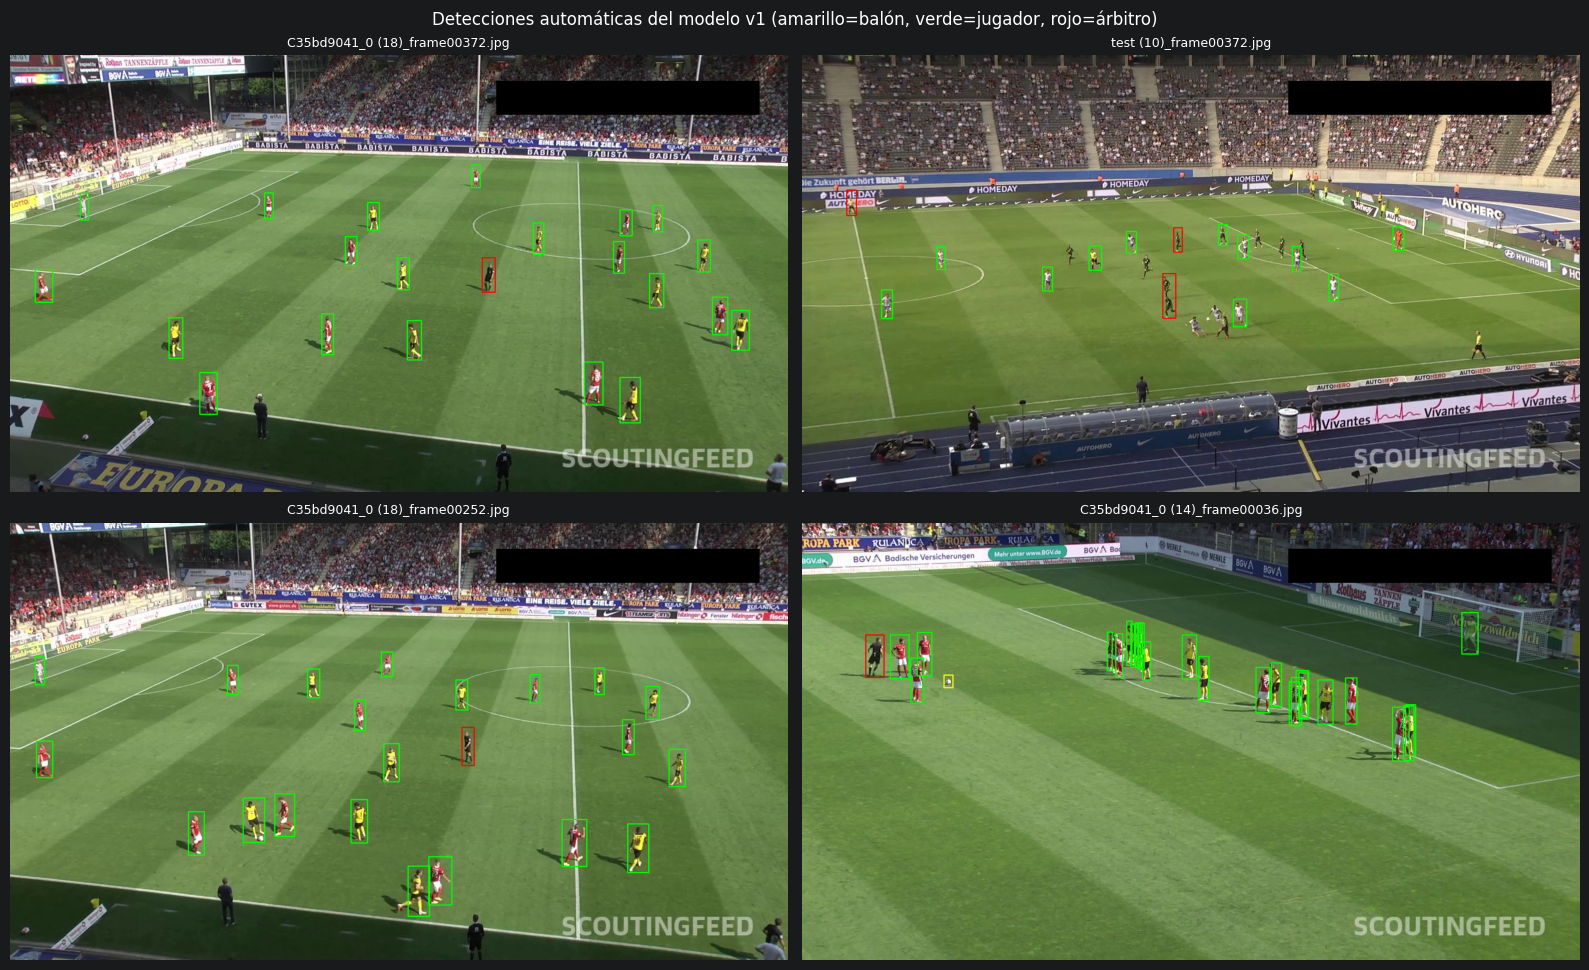

In [9]:
import matplotlib.pyplot as plt
import cv2
import random

# Colores por clase (BGR): ball=amarillo, player=verde, referee=rojo
COLORS = {0: (0, 255, 255), 1: (0, 255, 0), 2: (0, 0, 255)}
CLASS_NAMES = {0: "ball", 1: "player", 2: "referee"}

muestras = random.sample(list(images_out.glob("*.jpg")), 4)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, img_path in zip(axes.flat, muestras):
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    label_path = labels_out / (img_path.stem + ".txt")
    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                cls, xc, yc, bw, bh = map(float, line.split())
                cls = int(cls)
                x1 = int((xc - bw/2) * w)
                y1 = int((yc - bh/2) * h)
                x2 = int((xc + bw/2) * w)
                y2 = int((yc + bh/2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[cls], 2)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.suptitle("Detecciones automáticas del modelo v1 (amarillo=balón, verde=jugador, rojo=árbitro)", fontsize=12)
plt.tight_layout()
plt.show()

## 7. Conclusiones

Tras este notebook:

- El modelo v1 ha generado anotaciones automáticas para todos los frames del dataset.
- La media de detecciones por frame es coherente con la presencia esperada de jugadores, árbitros y balón en cada escena.
- Estas anotaciones constituyen el punto de partida para la revisión manual, que se realiza en Roboflow.
- Como se observa en la visualización, el modelo detecta bien jugadores y árbitros, pero el balón se detecta con menor frecuencia, lo que confirma la necesidad de reforzarlo manualmente durante la revisión.

El siguiente notebook documenta la subida de estas anotaciones a Roboflow.

In [10]:
from pathlib import Path

REPO_ROOT = Path("../..").resolve()  # ajusta si lo ejecutas desde otro sitio

print("ESTRUCTURA DEL PROYECTO\n" + "="*50)

def mostrar_arbol(directorio, prefijo="", nivel=0, max_nivel=2):
    if nivel > max_nivel:
        return
    items = sorted(directorio.iterdir(), key=lambda x: (x.is_file(), x.name))
    for item in items:
        if item.name in {".git", ".venv", "__pycache__", ".ipynb_checkpoints", ".idea"}:
            continue
        if item.is_dir():
            n_archivos = sum(1 for _ in item.rglob("*") if _.is_file())
            print(f"{prefijo}📁 {item.name}/ ({n_archivos} archivos)")
            mostrar_arbol(item, prefijo + "   ", nivel + 1, max_nivel)
        else:
            size = item.stat().st_size / (1024*1024)
            print(f"{prefijo}📄 {item.name} ({size:.1f} MB)")

mostrar_arbol(REPO_ROOT)

ESTRUCTURA DEL PROYECTO
📁 configs/ (0 archivos)
📁 data/ (2589 archivos)
   📁 auto_labeled/ (1512 archivos)
      📁 images/ (756 archivos)
      📁 labels/ (756 archivos)
   📁 dataset/ (309 archivos)
      📁 images/ (0 archivos)
      📁 labels/ (0 archivos)
      📁 train/ (259 archivos)
      📁 valid/ (47 archivos)
      📄 README.dataset.txt (0.0 MB)
      📄 README.roboflow.txt (0.0 MB)
      📄 data.yaml (0.0 MB)
   📁 frames/ (756 archivos)
      📁 A1606b0e6_0 (12)/ (63 archivos)
      📁 A1606b0e6_0 (21)/ (63 archivos)
      📁 A1606b0e6_0 (26)/ (63 archivos)
      📁 A1606b0e6_0 (37)/ (63 archivos)
      📁 A1606b0e6_0 (62)/ (63 archivos)
      📁 A1606b0e6_0 (7)/ (63 archivos)
      📁 A1606b0e6_0 (9)/ (63 archivos)
      📁 C35bd9041_0 (14)/ (63 archivos)
      📁 C35bd9041_0 (18)/ (63 archivos)
      📁 E3c993bd2_0 (13)/ (63 archivos)
      📁 test (10)/ (63 archivos)
      📁 test (27)/ (63 archivos)
   📁 labels/ (0 archivos)
   📁 raw/ (12 archivos)
      📄 A1606b0e6_0 (12).mp4 (23.5 MB)
    